# Week 2 — Data Collection & Sampling
### SENG 42293 Big Data Analytics

This notebook walks through the Week 2 slides hands-on: every technique gets a runnable,
checkable demonstration on real (simulated) data — not just a definition.

**Agenda**
1. Building our "population" — 10,000 students across 4 faculties
2. Batch vs. streaming collection
3. Why sample at all? (a timing demonstration)
4. The four classical sampling techniques, compared against the true population
5. Sampling bias, quantified
6. How big should your sample be? (the formula, and a convergence demo)
7. Reservoir sampling — implementation + a fairness check
8. Sketching for streams — Count-Min Sketch & HyperLogLog vs. exact counting
9. Lab exercise for you


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import time
import sys
from collections import Counter
from datasketch import HyperLogLog

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
%matplotlib inline

rng = np.random.default_rng(7)


## 1. Building Our "Population"

Every sampling technique needs something to sample *from*. We'll simulate the exact scenario
from the slides: **10,000 students across 4 faculties**, being surveyed on cafeteria
satisfaction (0–10 scale). Because this is simulated, we actually *know* the true population
mean — which lets us check, honestly, how close each sampling technique gets.

Each faculty is given a different true satisfaction level on purpose, so that a sampling
method which distorts faculty proportions will visibly distort the estimate too.


In [2]:
N = 10_000
faculties = rng.choice(
    ["Science", "Engineering", "Arts", "Business"],
    size=N, p=[0.30, 0.25, 0.25, 0.20]
)
# true (population) mean satisfaction per faculty -- deliberately different,
# so sampling bias will be visible later
faculty_true_mean = {"Science": 6.5, "Engineering": 7.2, "Arts": 5.8, "Business": 6.0}
satisfaction = np.array([rng.normal(faculty_true_mean[f], 1.2) for f in faculties]).clip(0, 10)

students = pd.DataFrame({
    "StudentID": np.arange(1, N + 1),
    "Faculty": faculties,
    "Satisfaction": satisfaction.round(2),
})
# assign each student to one of 200 tutorial groups (~50 students each) for cluster sampling
students["TutorialGroup"] = (students.index % 200) + 1

true_population_mean = students["Satisfaction"].mean()
print("Population shape:", students.shape)
print(students.groupby("Faculty")["Satisfaction"].agg(["count", "mean"]).round(2))
print("\nTRUE population mean satisfaction:", round(true_population_mean, 3))


Population shape: (10000, 4)
             count  mean
Faculty                 
Arts          2484  5.81
Business      2053  5.98
Engineering   2442  7.21
Science       3021  6.48

TRUE population mean satisfaction: 6.393


In [3]:
students.to_csv("student_population.csv", index=False)
print("Saved student_population.csv --", students.shape[0], "rows")


Saved student_population.csv -- 10000 rows


## 2. Batch vs. Streaming Collection

- **Batch collection**: a bulk snapshot, loaded all at once — you can see its full size
  immediately.
- **Streaming collection**: events arrive one at a time, and you can't know in advance how
  many there will be, or rewind to see an earlier one again. We simulate this with a Python
  **generator** — it genuinely only yields one event at a time, just like a real stream would.


In [4]:
def event_stream(n_events):
    """Simulates a live, unbounded event stream: read-once, forward-only,
    length unknown until it ends."""
    for i in range(n_events):
        yield {"event_id": i, "value": rng.normal(50, 5)}

batch = students.head(500).copy()
print("Batch collection: loaded", len(batch), "rows in one shot")

stream_preview = [event for event in event_stream(5)]
print("Streaming collection: events arrive one at a time, e.g.:", stream_preview[0])


Batch collection: loaded 500 rows in one shot
Streaming collection: events arrive one at a time, e.g.: {'event_id': 0, 'value': 41.94225900755456}


## 3. Why Sample at All?

A direct, timed comparison: process all 5,000,000 rows vs. a 1% sample, and look at both the
speed difference and how close the sample's estimate lands to the full-data answer.


In [5]:
big = rng.normal(100, 15, 5_000_000)

t0 = time.perf_counter()
full_mean = big.mean()
t_full = time.perf_counter() - t0

sample_1pct = rng.choice(big, size=int(len(big) * 0.01), replace=False)
t0 = time.perf_counter()
sample_mean = sample_1pct.mean()
t_sample = time.perf_counter() - t0

print(f"Full data (5,000,000 rows): mean={full_mean:.4f}, time={t_full*1000:.2f} ms")
print(f"1% sample   ({len(sample_1pct):,} rows): mean={sample_mean:.4f}, time={t_sample*1000:.2f} ms")
print(f"Speedup: {t_full/t_sample:.1f}x faster, estimate off by only {abs(full_mean-sample_mean):.4f}")


Full data (5,000,000 rows): mean=99.9984, time=3.73 ms
1% sample   (50,000 rows): mean=100.0147, time=0.11 ms
Speedup: 34.7x faster, estimate off by only 0.0163


## 4. The Four Classical Sampling Techniques

The same worked example as the slides: sample `n=400` students out of the 10,000, four
different ways, and compare each estimate against the **true** population mean we computed
in Section 1.


In [6]:
SAMPLE_N = 400

# -- Random: every student has an equal chance --
random_sample = students.sample(n=SAMPLE_N, random_state=1)

# -- Stratified: sample proportionally from each faculty --
def stratified_sample(frame, strata_col, n_total, seed=1):
    parts = []
    for stratum, group in frame.groupby(strata_col):
        stratum_n = round(n_total * len(group) / len(frame))
        parts.append(group.sample(n=stratum_n, random_state=seed))
    return pd.concat(parts, ignore_index=True)

stratified = stratified_sample(students, "Faculty", SAMPLE_N)

# -- Systematic: every k-th row after a random start --
def systematic_sample(frame, n_total, seed=1):
    k = len(frame) // n_total
    rs = np.random.default_rng(seed)
    start = rs.integers(0, k)
    idx = np.arange(start, len(frame), k)[:n_total]
    return frame.iloc[idx]

systematic = systematic_sample(students.reset_index(drop=True), SAMPLE_N)

# -- Cluster: randomly pick whole tutorial groups, use everyone in them --
def cluster_sample(frame, cluster_col, approx_n, seed=1):
    rs = np.random.default_rng(seed)
    cluster_sizes = frame.groupby(cluster_col).size()
    n_clusters = max(1, round(approx_n / cluster_sizes.mean()))
    chosen = rs.choice(cluster_sizes.index, size=n_clusters, replace=False)
    return frame[frame[cluster_col].isin(chosen)]

cluster = cluster_sample(students, "TutorialGroup", SAMPLE_N)

print("Sample sizes -> random:", len(random_sample), "| stratified:", len(stratified),
      "| systematic:", len(systematic), "| cluster:", len(cluster))


Sample sizes -> random: 400 | stratified: 400 | systematic: 400 | cluster: 400


In [7]:
comparison = pd.DataFrame({
    "Technique": ["Random", "Stratified", "Systematic", "Cluster"],
    "n": [len(random_sample), len(stratified), len(systematic), len(cluster)],
    "Estimated mean": [
        random_sample["Satisfaction"].mean(),
        stratified["Satisfaction"].mean(),
        systematic["Satisfaction"].mean(),
        cluster["Satisfaction"].mean(),
    ],
})
comparison["Error vs true mean"] = (comparison["Estimated mean"] - true_population_mean).round(4)
comparison


,Technique,n,Estimated mean,Error vs true mean
0,Random,400,6.307025,-0.0864
1,Stratified,400,6.360350,-0.0331
2,Systematic,400,6.421000,0.0276
3,Cluster,400,6.364425,-0.0290


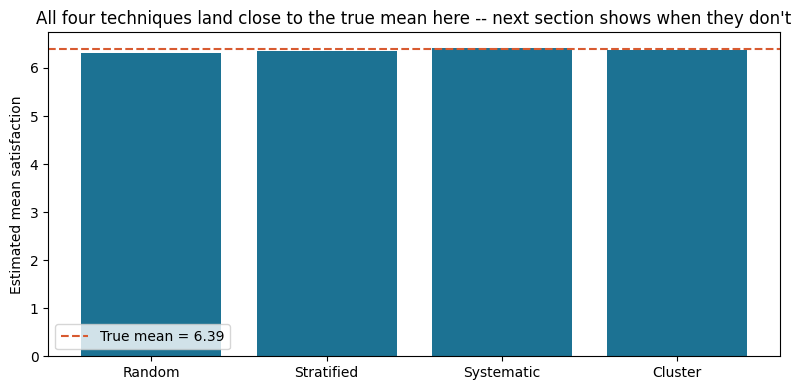

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(comparison["Technique"], comparison["Estimated mean"], color="#1C7293")
ax.axhline(true_population_mean, color="#D85A30", linestyle="--",
           label=f"True mean = {true_population_mean:.2f}")
ax.set_ylabel("Estimated mean satisfaction")
ax.set_title("All four techniques land close to the true mean here -- next section shows when they don't")
ax.legend()
plt.tight_layout()
plt.show()


### Does stratified really preserve proportions better?

Compare each sample's faculty composition against the true population composition.


In [9]:
comp_table = pd.DataFrame({
    "Population %": (students["Faculty"].value_counts(normalize=True) * 100).round(1),
    "Random sample %": (random_sample["Faculty"].value_counts(normalize=True) * 100).round(1),
    "Stratified sample %": (stratified["Faculty"].value_counts(normalize=True) * 100).round(1),
})
comp_table


,Population %,Random sample %,Stratified sample %
Faculty,,,
Science,30.2,30.2,30.2
Arts,24.8,25.0,24.8
Engineering,24.4,24.5,24.5
Business,20.5,20.2,20.5


## 5. Sampling Bias, Quantified

Recall the "Spot the Bias" scenario: *"A university measures student satisfaction from a form
linked only on the library's homepage."* Let's actually simulate that kind of selection bias
and see what it does to the estimate, side-by-side with a proper random sample of the same size.

We model library-goers as skewing toward Science/Engineering students (plausible — and in our
simulation, those are also the happier faculties), which is exactly the kind of confound that
makes selection bias dangerous: it's invisible unless you know to look for it.


In [10]:
library_user_prob = students["Faculty"].map({
    "Science": 0.55, "Engineering": 0.50, "Arts": 0.20, "Business": 0.15
}).values
is_library_user = rng.random(N) < library_user_prob
biased_frame = students[is_library_user]
biased_sample = biased_frame.sample(n=min(SAMPLE_N, len(biased_frame)), random_state=1)

proper_random_sample = students.sample(n=SAMPLE_N, random_state=2)

print("Biased (library-survey) sample composition:")
print((biased_sample["Faculty"].value_counts(normalize=True) * 100).round(1))
print("\nProper random sample composition:")
print((proper_random_sample["Faculty"].value_counts(normalize=True) * 100).round(1))


Biased (library-survey) sample composition:
Faculty
Science        43.5
Engineering    33.5
Arts           14.8
Business        8.2
Name: proportion, dtype: float64

Proper random sample composition:
Faculty
Science        28.7
Arts           27.0
Engineering    24.2
Business       20.0
Name: proportion, dtype: float64


True population mean:          6.393


Biased sample estimate:        6.590  (error: +0.196)
Proper random sample estimate: 6.453  (error: +0.059)


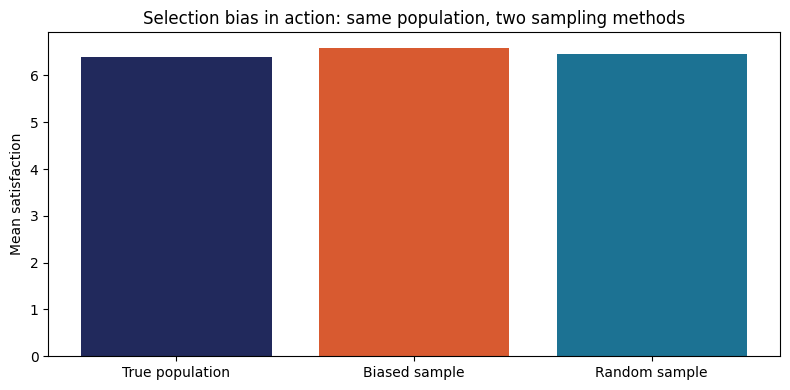

In [11]:
bias_error = biased_sample["Satisfaction"].mean() - true_population_mean
random_error = proper_random_sample["Satisfaction"].mean() - true_population_mean

print(f"True population mean:          {true_population_mean:.3f}")
print(f"Biased sample estimate:        {biased_sample['Satisfaction'].mean():.3f}  (error: {bias_error:+.3f})")
print(f"Proper random sample estimate: {proper_random_sample['Satisfaction'].mean():.3f}  (error: {random_error:+.3f})")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(["True population", "Biased sample", "Random sample"],
       [true_population_mean, biased_sample["Satisfaction"].mean(), proper_random_sample["Satisfaction"].mean()],
       color=["#21295C", "#D85A30", "#1C7293"])
ax.set_ylabel("Mean satisfaction")
ax.set_title("Selection bias in action: same population, two sampling methods")
plt.tight_layout()
plt.show()


The biased sample doesn't just have a different composition — it produces a **measurably
worse estimate** of the true population mean than an equally-sized proper random sample.
This is the concrete version of what "Spot the Bias" was asking you to reason about qualitatively.


## 6. How Big Should Your Sample Be?

The formula from the slides:

$$n = \frac{Z^2 \cdot p(1-p)}{e^2}$$

where `Z` is the confidence level's z-score, `p` is the estimated proportion (0.5 if unknown
— the safest choice), and `e` is the margin of error.


In [12]:
def required_sample_size(confidence_z, margin_of_error, p=0.5):
    return (confidence_z ** 2 * p * (1 - p)) / (margin_of_error ** 2)

n_95 = required_sample_size(confidence_z=1.96, margin_of_error=0.05)
print(f"Required n for 95% confidence, +/-5% margin: {n_95:.1f} -> round up to {int(np.ceil(n_95))}")


Required n for 95% confidence, +/-5% margin: 384.2 -> round up to 385


### Seeing it converge

The formula tells you the sample size needed for a *given* margin of error — but what does
convergence actually look like? Let's draw samples of growing size from our population and
watch the estimate settle toward the true mean.


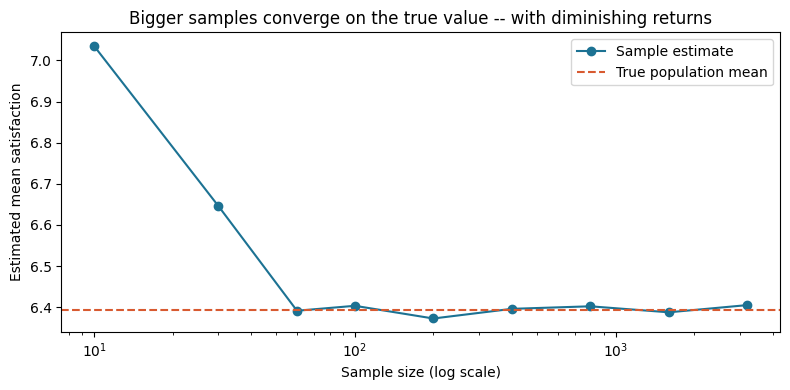

[(10, np.float64(7.035)),
 (30, np.float64(6.646)),
 (60, np.float64(6.391)),
 (100, np.float64(6.403)),
 (200, np.float64(6.373)),
 (400, np.float64(6.396)),
 (800, np.float64(6.402)),
 (1600, np.float64(6.388)),
 (3200, np.float64(6.405))]

In [13]:
sizes = [10, 30, 60, 100, 200, 400, 800, 1600, 3200]
estimates = [students.sample(n=s, random_state=3)["Satisfaction"].mean() for s in sizes]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sizes, estimates, marker="o", color="#1C7293", label="Sample estimate")
ax.axhline(true_population_mean, color="#D85A30", linestyle="--", label="True population mean")
ax.set_xscale("log")
ax.set_xlabel("Sample size (log scale)")
ax.set_ylabel("Estimated mean satisfaction")
ax.set_title("Bigger samples converge on the true value -- with diminishing returns")
ax.legend()
plt.tight_layout()
plt.show()

list(zip(sizes, np.round(estimates, 3)))


Notice how much the estimate jumps around between sizes 10 and 100, and how little it moves
between 800 and 3200 — that's the "diminishing returns" the slides mentioned, visible directly.


## 7. Reservoir Sampling — Implementation + a Fairness Check

The same algorithm from the slides, plus something the slides couldn't show you: a **Monte
Carlo check** that every item really does end up with an equal `k/N` chance of being selected,
regardless of when it arrived in the stream.


In [14]:
def reservoir_sample(stream, k, seed=None):
    rs = random.Random(seed)
    reservoir = []
    for i, item in enumerate(stream, start=1):
        if i <= k:
            reservoir.append(item)
        else:
            j = rs.randint(1, i)
            if j <= k:
                reservoir[j - 1] = item
    return reservoir

demo_stream = ["A", "B", "C", "D", "E", "F", "G"]
print("Reservoir (k=3) over", demo_stream, "->", reservoir_sample(demo_stream, 3, seed=1))


Reservoir (k=3) over ['A', 'B', 'C', 'D', 'E', 'F', 'G'] -> ['F', 'D', 'G']


Expected selection probability per item: 0.1000
Observed (min / mean / max over 50 items): 0.0962 / 0.1000 / 0.1039


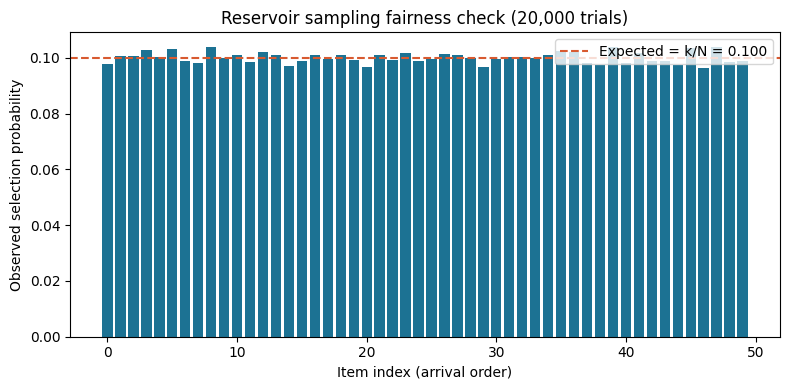

In [15]:
# Monte Carlo check: run the algorithm thousands of times over the SAME stream
# and tally how often each item ends up in the final reservoir.
N_ITEMS, K = 50, 5
TRIALS = 20_000
counts = np.zeros(N_ITEMS)
for t in range(TRIALS):
    res = reservoir_sample(range(N_ITEMS), K, seed=t)
    for item in res:
        counts[item] += 1

observed_prob = counts / TRIALS
expected_prob = K / N_ITEMS
print(f"Expected selection probability per item: {expected_prob:.4f}")
print(f"Observed (min / mean / max over {N_ITEMS} items): "
      f"{observed_prob.min():.4f} / {observed_prob.mean():.4f} / {observed_prob.max():.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(N_ITEMS), observed_prob, color="#1C7293")
ax.axhline(expected_prob, color="#D85A30", linestyle="--", label=f"Expected = k/N = {expected_prob:.3f}")
ax.set_xlabel("Item index (arrival order)")
ax.set_ylabel("Observed selection probability")
ax.set_title(f"Reservoir sampling fairness check ({TRIALS:,} trials)")
ax.legend()
plt.tight_layout()
plt.show()


The bars are flat around the expected line regardless of arrival position (index 0 is no more
or less likely than index 49) — exactly the "every record ends up with an equal k/N chance"
claim from the slides, verified empirically rather than just asserted.


## 8. Sketching for Streams — Approximate vs. Exact

We'll simulate a stream of 200,000 visit events drawn from 40,000 possible unique visitor IDs,
then compare three ways of answering "how many distinct visitors?" and "how many times did
visitor X show up?": an **exact** approach, **HyperLogLog**, and a **Count-Min Sketch**.


In [16]:
STREAM_LEN = 200_000
TRUE_UNIQUE = 40_000
event_stream_ids = rng.integers(0, TRUE_UNIQUE, size=STREAM_LEN).astype(str)

# --- Exact: a Python set (for uniques) and Counter (for frequencies) ---
exact_unique = set(event_stream_ids)
exact_unique_count = len(exact_unique)
exact_set_bytes = sys.getsizeof(exact_unique) + sum(sys.getsizeof(x) for x in list(exact_unique)[:1000]) * (len(exact_unique) / 1000)

exact_counts = Counter(event_stream_ids)
# sys.getsizeof() on a dict only measures the container, not what it holds --
# ~100 bytes/entry is a more realistic estimate for a Python dict of (str, int)
exact_freq_bytes = len(exact_counts) * 100


In [17]:
# --- HyperLogLog: approximate distinct count ---
hll = HyperLogLog(p=12)  # 4096 registers -> standard error ~1.04/sqrt(4096) ~ 1.6%
for eid in event_stream_ids:
    hll.update(eid.encode("utf8"))
hll_estimate = hll.count()
hll_bytes = 2 ** 12  # one byte per register

print(f"True unique IDs:      {TRUE_UNIQUE:,}")
print(f"Exact count (set):    {exact_unique_count:,}  (memory ~{exact_set_bytes/1024:.1f} KB)")
print(f"HyperLogLog estimate: {hll_estimate:,.0f}  "
      f"(error: {abs(hll_estimate-TRUE_UNIQUE)/TRUE_UNIQUE*100:.2f}%, memory ~{hll_bytes/1024:.1f} KB)")


True unique IDs:      40,000
Exact count (set):    39,745  (memory ~4754.8 KB)
HyperLogLog estimate: 40,217  (error: 0.54%, memory ~4.0 KB)


In [18]:
# --- Count-Min Sketch: approximate frequency counting (simple manual implementation) ---
def make_cms(width, depth, seed=0):
    rs = np.random.default_rng(seed)
    salts = rs.integers(0, 2**31 - 1, size=depth)
    table = np.zeros((depth, width), dtype=np.int64)
    return table, salts

def cms_add(table, salts, width, key):
    for row, salt in enumerate(salts):
        col = (hash((key, int(salt))) % width + width) % width
        table[row, col] += 1

def cms_estimate(table, salts, width, key):
    return min(table[row, (hash((key, int(salt))) % width + width) % width]
               for row, salt in enumerate(salts))

WIDTH, DEPTH = 20_000, 4
cms_table, cms_salts = make_cms(WIDTH, DEPTH)
for eid in event_stream_ids:
    cms_add(cms_table, cms_salts, WIDTH, eid)

most_common = exact_counts.most_common(5)
print(f"{'ID':>8} {'exact':>8} {'CMS est.':>9}")
for key, true_count in most_common:
    est = cms_estimate(cms_table, cms_salts, WIDTH, key)
    print(f"{key:>8} {true_count:>8} {est:>9}")

cms_bytes = cms_table.nbytes
print(f"\nCount-Min Sketch memory: {cms_bytes/1024:.1f} KB  (width={WIDTH}, depth={DEPTH})")
print(f"Exact frequency table (dict of counts) memory: ~{exact_freq_bytes/1024:.1f} KB (rough estimate)")


      ID    exact  CMS est.
   27287       18        23
   14696       17        17
   23840       16        28
   34903       16        25
   27783       16        22

Count-Min Sketch memory: 625.0 KB  (width=20000, depth=4)
Exact frequency table (dict of counts) memory: ~3881.3 KB (rough estimate)


Two things worth noticing in the output above:
- The Count-Min Sketch **never underestimates** — every estimate is greater than or equal to
  the true count, exactly as the slides described (collisions only ever inflate a count).
- Both sketches use a small, *fixed* amount of memory no matter how long the stream runs,
  while the exact approaches grow with the number of unique items seen.


## 9. Lab Exercise for You

Using `student_population.csv` (or the `students` DataFrame already in memory), extend this notebook:

- [ ] **Sampling**: repeat the four-technique comparison (Section 4) but sample only `n=50`
  instead of 400. Which technique's estimate degrades the most, and why?
- [ ] **Bias**: design your own biased sampling scenario (pick a different confound — e.g.
  students who reply to evening notifications) and quantify the resulting error, the same way
  Section 5 did.
- [ ] **Sample size**: use `required_sample_size()` to compute `n` for a 99% confidence level
  at a ±3% margin of error. How much bigger is it than the 95%/±5% example?
- [ ] **Reservoir sampling**: modify `reservoir_sample()` to implement the **weighted** variant
  (Algorithm A-Res) mentioned in the slides, where items with a higher weight are more likely
  to be kept.
- [ ] **Sketching**: increase `TRUE_UNIQUE` to 4,000,000 and re-run the HyperLogLog comparison.
  Does the memory usage change? Does the error rate?
- [ ] **Deliverable**: for each task above, add a markdown cell explaining what you expected
  to happen *before* you ran the cell, and whether the result matched.

### Wrap-up & Next Week

**Today's key takeaways**
- Data comes structured, semi-structured, and unstructured — each collected (and challenged) differently
- Sampling trades a little precision for a lot of speed and cost savings — but watch for bias
- Required sample size grows with confidence and precision, not population size
- Reservoir sampling and sketches make sampling work even on unbounded streams

**Next week: Data Quality & Pre-processing I**
- Data quality dimensions: completeness, accuracy, consistency, timeliness
- Handling missing values, duplicates, and outliers
- Encoding categorical variables, normalization
